# **Structural Damage Classification EDA**

# **Import Library**

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# **Import Data**

In [27]:
data_dir = "../data"
train = pd.read_csv(f"{data_dir}/train.csv")
test = pd.read_csv(f"{data_dir}/test.csv")
sample_sub = pd.read_csv(f"{data_dir}/sample_submission.csv")

train.shape, test.shape, sample_sub.shape

((533465, 17), (228629, 16), (228629, 2))

In [28]:
train = pd.read_csv(f"{data_dir}/train.csv")
test = pd.read_csv(f"{data_dir}/test.csv")
sample_sub = pd.read_csv(f"{data_dir}/sample_submission.csv")
meta = pd.read_csv(f"{data_dir}/metadata.csv")

train.shape, test.shape, sample_sub.shape

((533465, 17), (228629, 16), (228629, 2))

In [29]:
meta

,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number
5,age_building,Age of the building (in years),Number
6,plinth_area_sq_ft,Plinth area of the building (in square feet),Number
7,height_ft_pre_eq,Height of the building before the earthquake (...,Number
8,land_surface_condition,Surface condition of the land in which the bui...,Categorical
9,foundation_type,Type of foundation used in the building,Categorical


# **Quick EDA**

In [30]:
train.head()

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


In [31]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [32]:
print("Missing (train):", train.isna().sum().sum(), "| Missing (test):", test.isna().sum().sum())
print("Duplicate building_id (train):", train.building_id.duplicated().sum())
print("building_id overlap train/test:", len(set(train.building_id) & set(test.building_id)))
print("Columns only in train:", set(train.columns) - set(test.columns))

Missing (train): 0 | Missing (test): 0
Duplicate building_id (train): 0
building_id overlap train/test: 0
Columns only in train: {'damage_grade'}


## Target

grade
1    0.1034
2    0.1145
3    0.1790
4    0.2412
5    0.3619
Name: proportion, dtype: float64


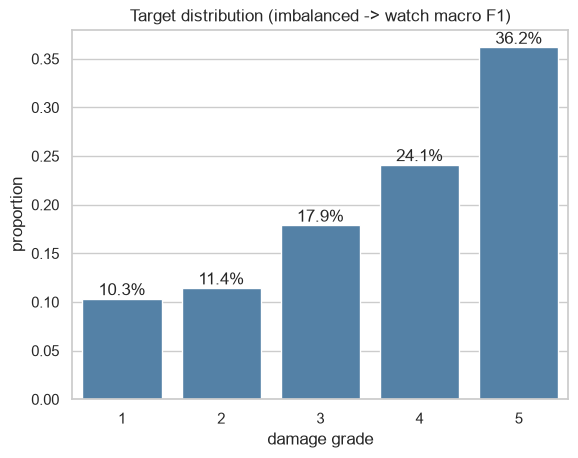

In [33]:
train["grade"] = train.damage_grade.str[-1].astype(int)

dist = train.grade.value_counts(normalize=True).sort_index()
print(dist.round(4))

ax = sns.barplot(x=dist.index, y=dist.values, color="steelblue")
ax.bar_label(ax.containers[0], labels=[f"{v:.1%}" for v in dist.values])
ax.set(xlabel="damage grade", ylabel="proportion", title="Target distribution (imbalanced -> watch macro F1)")
plt.show()

## Numeric features

In [34]:
num_cols = ["count_floors_pre_eq", "age_building", "plinth_area_sq_ft", "height_ft_pre_eq"]
train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


In [35]:
a = train.age_building
print("age == 0  :", (a == 0).sum())
print("age >= 200:", (a >= 200).sum(), "| age == 999:", (a == 999).sum())
print("test age >= 200:", (test.age_building >= 200).sum())

bins = [-1, 0, 5, 10, 20, 30, 50, 100, 199, 999]
age_tbl = train.groupby(pd.cut(a, bins), observed=True).grade.agg(["size", "mean"]).round(3)
age_tbl

age == 0  : 3349
age >= 200: 2376 | age == 999: 2198
test age >= 200: 1028


,size,mean
age_building,,
"(-1, 0]",3349,2.186
"(0, 5]",82458,2.978
"(5, 10]",84889,3.376
"(10, 20]",164574,3.723
"(20, 30]",100310,3.950
"(30, 50]",68654,4.048
"(50, 100]",26036,4.055
"(100, 199]",819,3.956
"(199, 999]",2376,3.614


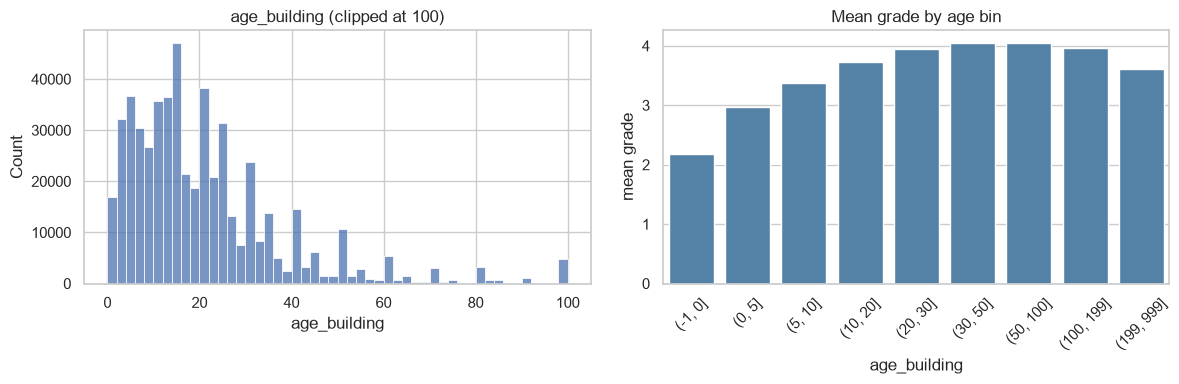

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(a.clip(upper=100), bins=50, ax=ax[0])
ax[0].set(title="age_building (clipped at 100)")
sns.barplot(x=age_tbl.index.astype(str), y=age_tbl["mean"], ax=ax[1], color="steelblue")
ax[1].set(title="Mean grade by age bin", ylabel="mean grade")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Size features** floors, height, plinth area vs mean damage grade.

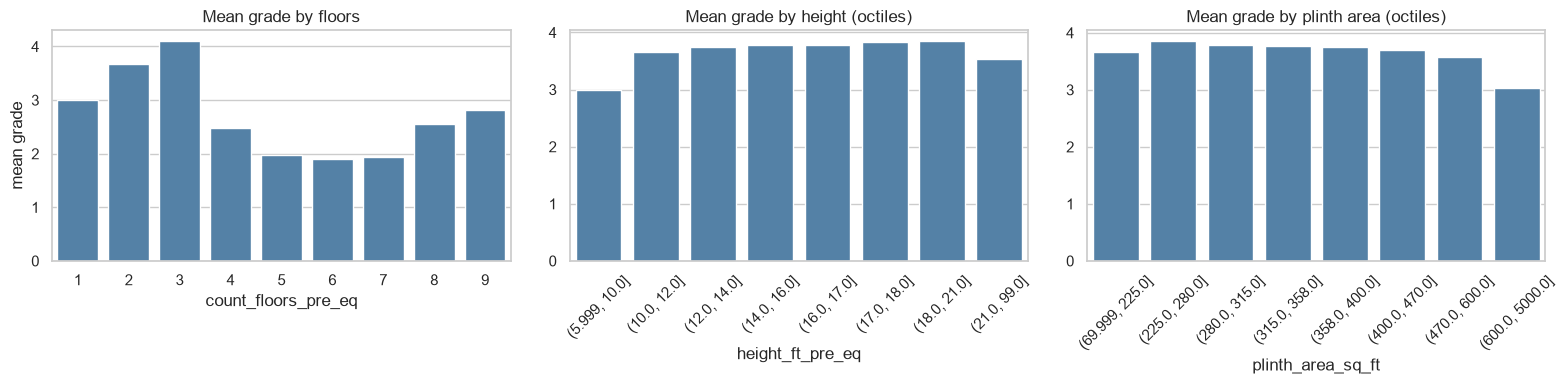

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

t = train.groupby("count_floors_pre_eq").grade.agg(["size", "mean"])
sns.barplot(x=t.index, y=t["mean"], ax=ax[0], color="steelblue")
ax[0].set(title="Mean grade by floors", ylabel="mean grade")

t = train.groupby(pd.qcut(train.height_ft_pre_eq, 8, duplicates="drop"), observed=True).grade.mean()
sns.barplot(x=t.index.astype(str), y=t.values, ax=ax[1], color="steelblue")
ax[1].set(title="Mean grade by height (octiles)"); ax[1].tick_params(axis="x", rotation=45)

t = train.groupby(pd.qcut(train.plinth_area_sq_ft, 8, duplicates="drop"), observed=True).grade.mean()
sns.barplot(x=t.index.astype(str), y=t.values, ax=ax[2], color="steelblue")
ax[2].set(title="Mean grade by plinth area (octiles)"); ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

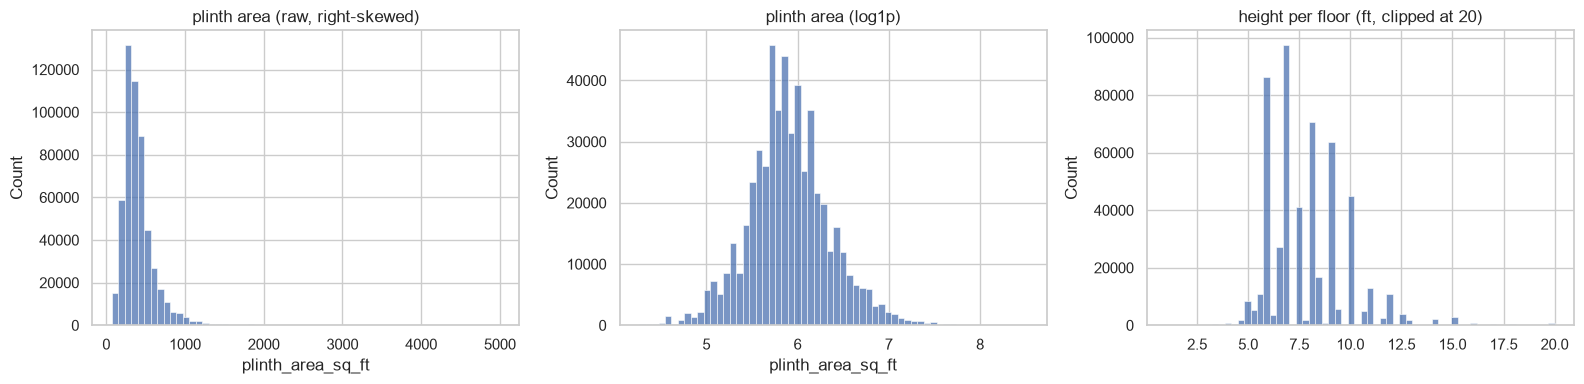

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train.plinth_area_sq_ft, bins=60, ax=ax[0]); ax[0].set(title="plinth area (raw, right-skewed)")
sns.histplot(np.log1p(train.plinth_area_sq_ft), bins=60, ax=ax[1]); ax[1].set(title="plinth area (log1p)")
sns.histplot((train.height_ft_pre_eq / train.count_floors_pre_eq).clip(upper=20), bins=60, ax=ax[2])
ax[2].set(title="height per floor (ft, clipped at 20)")
plt.tight_layout(); plt.show()

## Categorical features

In [39]:
cat_cols = ["land_surface_condition", "foundation_type", "roof_type", "ground_floor_type",
            "other_floor_type", "position", "plan_configuration", "superstructure"]

for c in cat_cols:
    print(f"{c:24s} {train[c].nunique():>3} categories")

land_surface_condition     3 categories
foundation_type            5 categories
roof_type                  3 categories
ground_floor_type          5 categories
other_floor_type           4 categories
position                   4 categories
plan_configuration        10 categories
superstructure            11 categories


In [40]:
def cat_summary(col):
    t = train.groupby(col).grade.agg(["size", "mean"]).round(3)
    t["share"] = (t["size"] / len(train)).round(4)
    return t.sort_values("mean")

cat_summary("foundation_type")

,size,mean,share
foundation_type,,,
RC,22445,1.598,0.0421
Bamboo/Timber,40167,2.492,0.0753
Cement-Stone/Brick,27562,2.634,0.0517
Other,3186,3.201,0.0060
Mud mortar-Stone/Brick,440105,3.919,0.8250


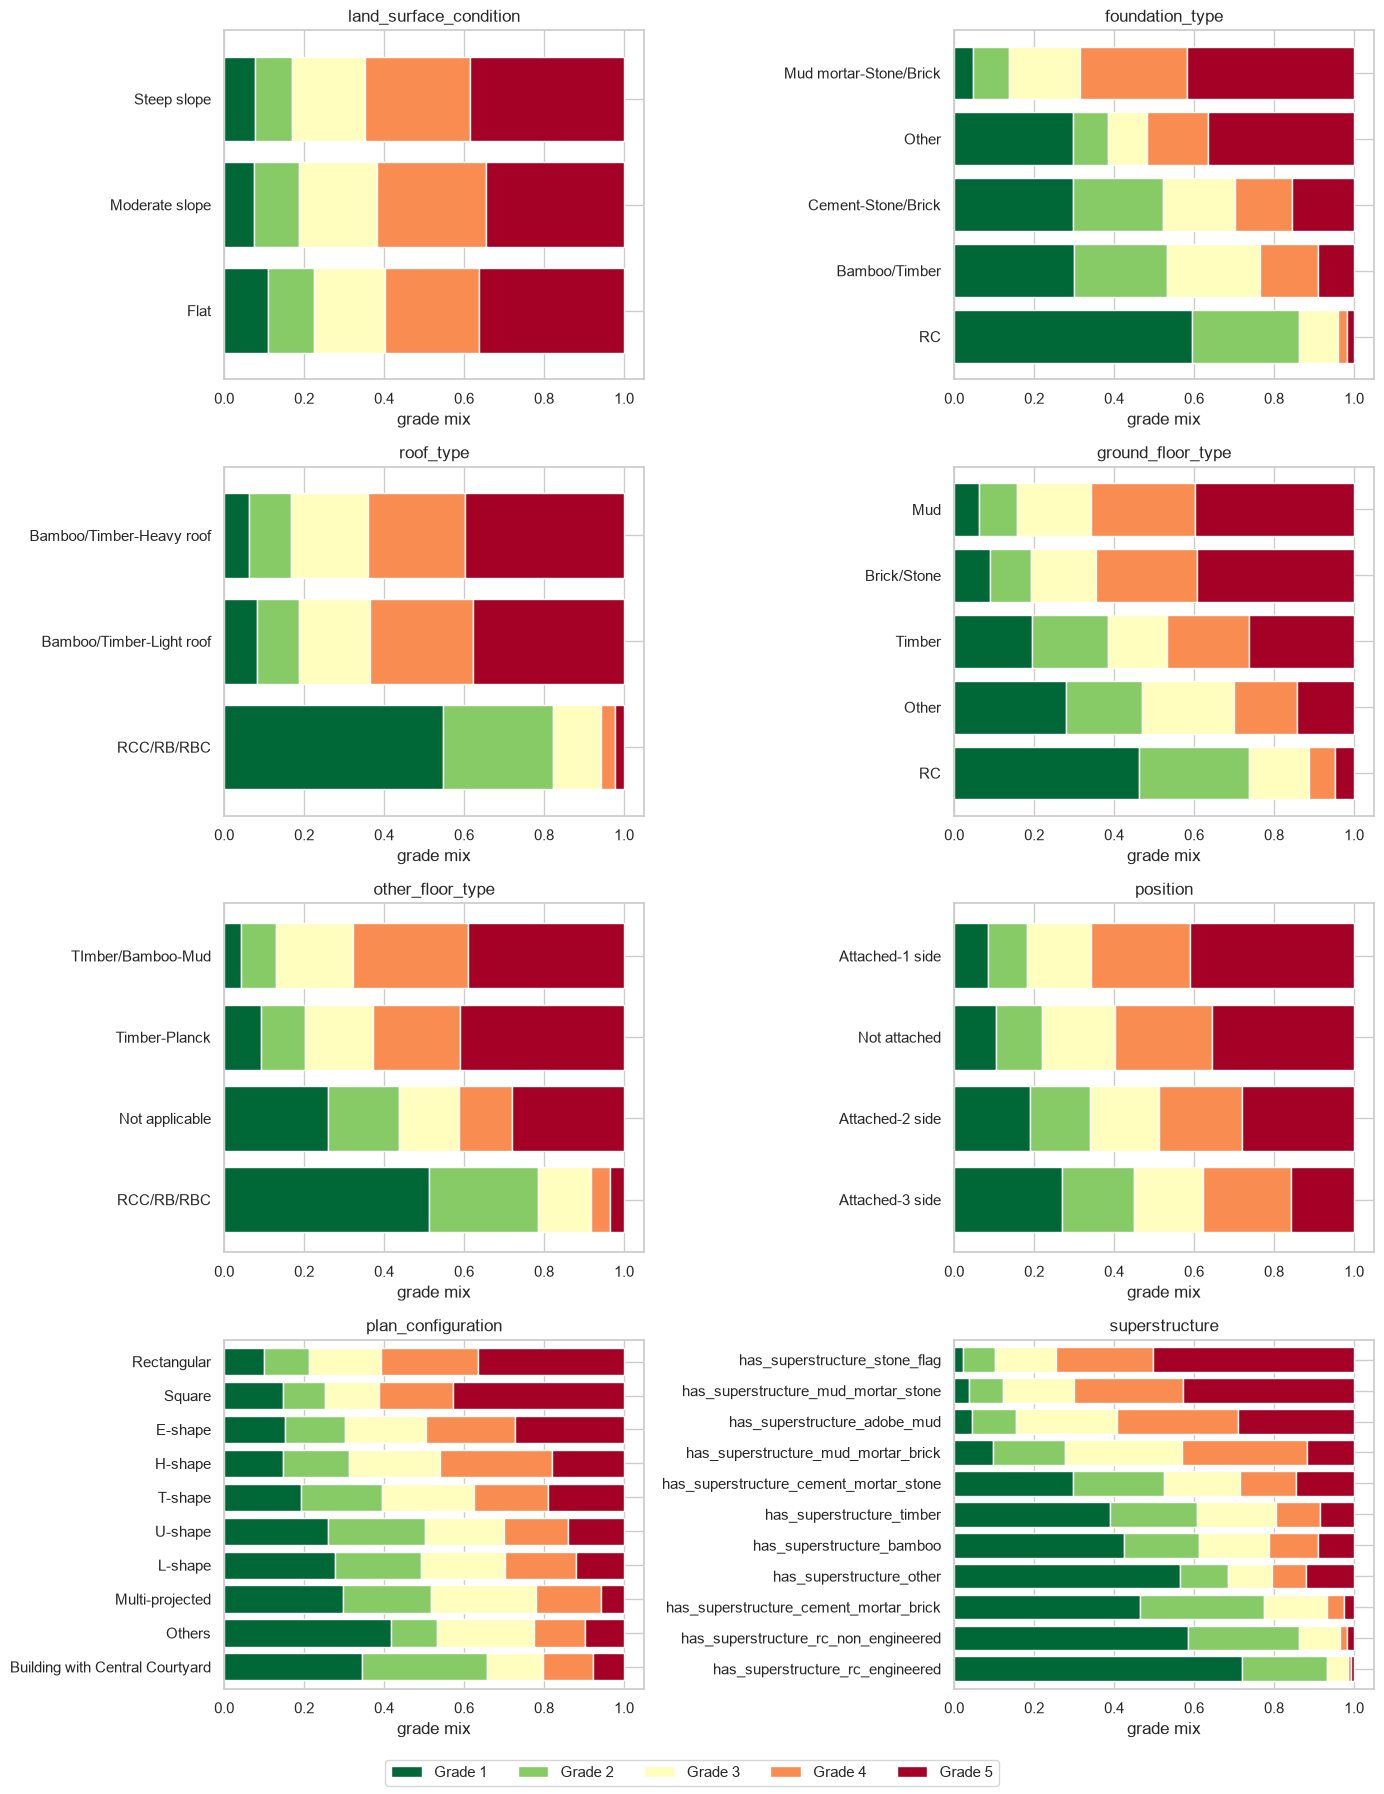

In [41]:
def plot_cat(col, ax):
    # 100% stacked bars: grade mix within each category, sorted by mean grade
    ct = pd.crosstab(train[col], train.grade, normalize="index")
    order = train.groupby(col).grade.mean().sort_values().index
    ct.loc[order].plot(kind="barh", stacked=True, ax=ax, colormap="RdYlGn_r", legend=False, width=0.8)
    ax.set(title=col, ylabel="", xlabel="grade mix")

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for c, ax in zip(cat_cols, axes.ravel()):
    plot_cat(c, ax)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, [f"Grade {l}" for l in labels], loc="lower center", ncol=5)
plt.tight_layout(rect=[0, 0.02, 1, 1]); plt.show()

In [42]:
for c in cat_cols:
    print(f"\n== {c}")
    print(cat_summary(c))


== land_surface_condition
                          size   mean   share
land_surface_condition                       
Flat                    442089  3.629  0.8287
Moderate slope           73944  3.699  0.1386
Steep slope              17432  3.786  0.0327

== foundation_type
                          size   mean   share
foundation_type                              
RC                       22445  1.598  0.0421
Bamboo/Timber            40167  2.492  0.0753
Cement-Stone/Brick       27562  2.634  0.0517
Other                     3186  3.201  0.0060
Mud mortar-Stone/Brick  440105  3.919  0.8250

== roof_type
                            size   mean   share
roof_type                                      
RCC/RB/RBC                 31136  1.714  0.0584
Bamboo/Timber-Light roof  352493  3.744  0.6608
Bamboo/Timber-Heavy roof  149836  3.807  0.2809

== ground_floor_type
                     size   mean   share
ground_floor_type                       
RC                  51146  1.961  0.0959
Ot

## Location (district / municipality / ward)

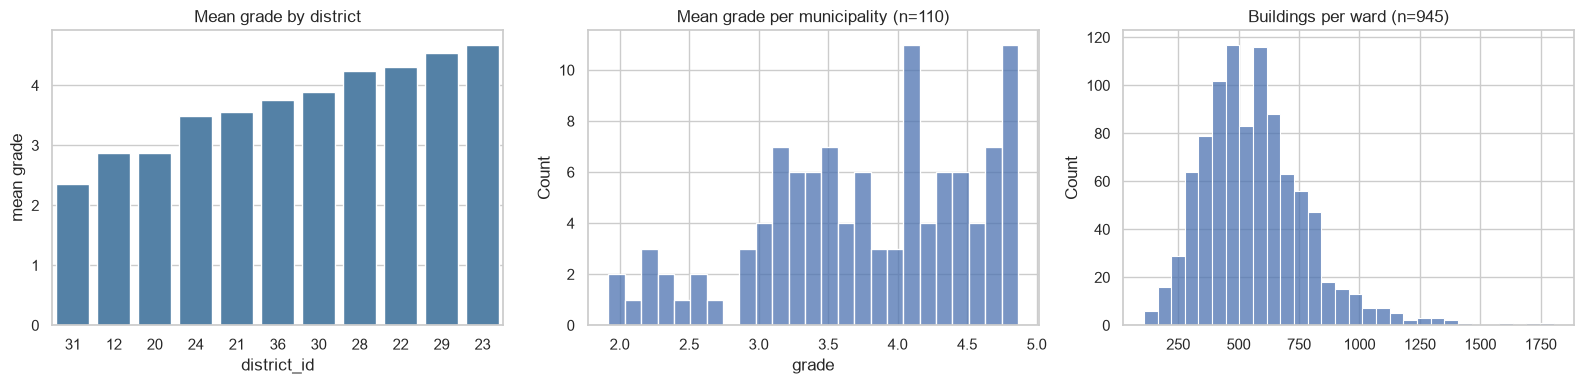

Test municipalities unseen in train: 0.0
Test wards unseen in train: 0.0


In [43]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

d = train.groupby("district_id").grade.mean().sort_values()
sns.barplot(x=d.index.astype(str), y=d.values, ax=ax[0], color="steelblue")
ax[0].set(title="Mean grade by district", xlabel="district_id", ylabel="mean grade")

v = train.groupby("vdcmun_id").grade.mean()
sns.histplot(v, bins=25, ax=ax[1]); ax[1].set(title=f"Mean grade per municipality (n={len(v)})")

w = train.groupby("ward_id").size()
sns.histplot(w, bins=30, ax=ax[2]); ax[2].set(title=f"Buildings per ward (n={len(w)})")
plt.tight_layout(); plt.show()

print("Test municipalities unseen in train:", (~test.vdcmun_id.isin(train.vdcmun_id)).mean())
print("Test wards unseen in train:", (~test.ward_id.isin(train.ward_id)).mean())

## Correlation of features with damage grade
Numeric features + one-hot categoricals vs the integer grade (Karena grade ordinal, menggunakan Spearman)

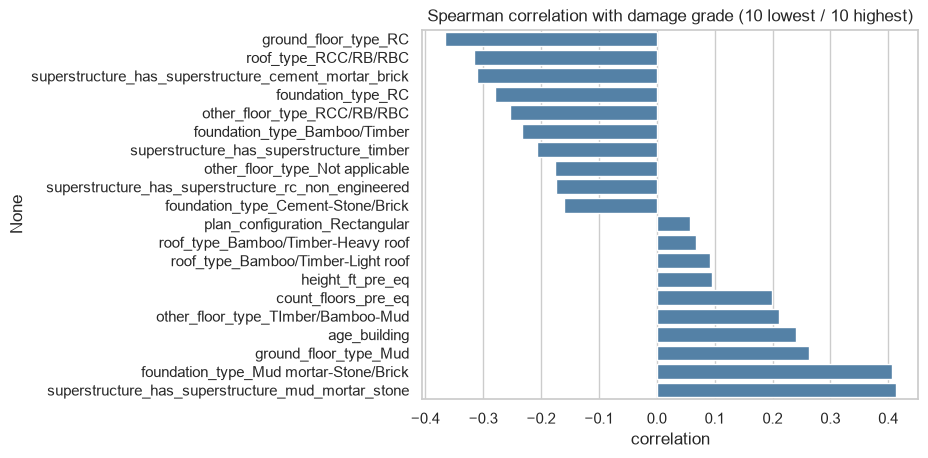

In [44]:
np.random.seed(17)

X = pd.get_dummies(train[cat_cols], dtype=int)
X[num_cols] = train[num_cols]
X["district_id"] = train.district_id
corr = X.corrwith(train.grade, method="spearman").sort_values()

top = pd.concat([corr.head(10), corr.tail(10)])
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("Spearman correlation with damage grade (10 lowest / 10 highest)")
plt.xlabel("correlation"); plt.show()

## building_id structure
cek ID untuk informasi geografis (ID berdekatan punya damage level yang sama)

In [45]:
b = train.building_id.astype(str)
print("ID length:", b.str.len().unique())
print("first 2 digits == district_id:", (b.str[:2].astype(int) == train.district_id).mean())

s = train.sort_values("building_id")
g = s.grade.values
same_ward = (s.ward_id.values[:-1] == s.ward_id.values[1:]).mean()
r_seq = np.corrcoef(g[:-1], g[1:])[0, 1]
r_shuf = np.corrcoef(g[:-1], np.random.permutation(g)[1:])[0, 1]
print(f"consecutive IDs in same ward: {same_ward:.3f}")
print(f"grade correlation, consecutive IDs: {r_seq:.3f} | shuffled: {r_shuf:.3f}")

ID length: [12]
first 2 digits == district_id: 1.0
consecutive IDs in same ward: 0.998
grade correlation, consecutive IDs: 0.583 | shuffled: 0.000


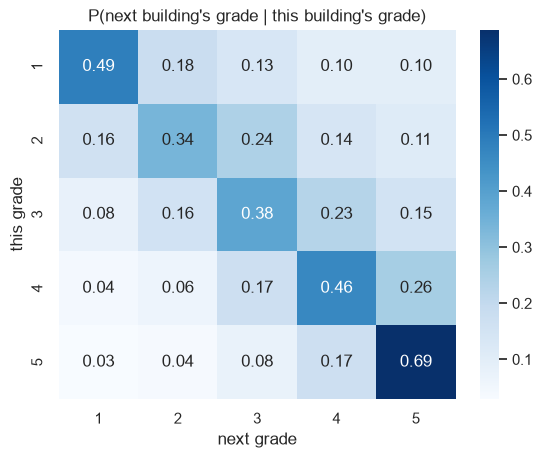

In [46]:
# grade of a building vs grade of the next building (sorted by ID), row-normalized
ct = pd.crosstab(g[:-1], g[1:], normalize="index")
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues")
plt.title("P(next building's grade | this building's grade)")
plt.xlabel("next grade"); plt.ylabel("this grade"); plt.show()

## Train vs test

In [47]:
shift = {}
for c in cat_cols + ["district_id", "count_floors_pre_eq"]:
    diff = (train[c].value_counts(normalize=True) - test[c].value_counts(normalize=True)).abs().max()
    shift[c] = diff
print("Max abs difference in category proportion, train vs test:")
print(pd.Series(shift).round(4).sort_values(ascending=False))

pd.DataFrame({"train": train[num_cols].mean(), "test": test[num_cols].mean()}).round(2)

Max abs difference in category proportion, train vs test:
district_id               0.0019
roof_type                 0.0012
plan_configuration        0.0008
position                  0.0007
superstructure            0.0006
foundation_type           0.0006
other_floor_type          0.0006
land_surface_condition    0.0005
ground_floor_type         0.0004
count_floors_pre_eq       0.0004
dtype: float64


,train,test
count_floors_pre_eq,2.09,2.09
age_building,24.34,24.30
plinth_area_sq_ft,406.52,407.02
height_ft_pre_eq,16.05,16.05


# **Hasil EDA -> Keputusan Preprocessing**
| Hasil | Keputusan |
|---|---|
| Kelas tidak seimbang (Grade 5 ≈ 36%, Grade 1 ≈ 10%) | class weight berbasis inverse frequency, offset per kelas disetel untuk macro F1 |
| `age_building` memiliki nilai placeholder 999 / >=200 | clip nilai di 200 dan menambah flag `age_unknown` |
| Material bangunan adalah sinyal struktural terkuat | tetap sebagai fitur kategorikal, menambah fitur `weakest_link` (tingkat keparahan material) |
| District / municipality / ward berbeda jauh pada rata-rata grade | tetap sebagai kolom kategorikal |
| `building_id` dengan id berdekatan memiliki grade yang berkorelasi (r ≈ 0.58) | fitur ID-neighbour dan label propagation, dibangun fold-aware (hanya memakai label dari fold lain) |
| Train dan test mirip, tidak ada ward yang tidak dikenal | stratified K-fold valid sebagai validasi |